# Face-level machining feature recognition with a GNN
**Task:** for every face of a CAD part, predict its feature class
(`stock, hole, slot, pocket, chamfer, fillet, boss, rib`).

**Data:** `data/graphs.pkl` from `build_graphs.py` (1000 parts, 11 node / 5 edge features).

**Models compared** (same data, same split, same loss):
1. **MLP baseline** - sees only each face's own 11 features (no neighbours)
2. **GNN (no edge features)** - sees neighbouring faces, but not convex/concave/angle info
3. **GNN (with edge features)** - full model

**Evaluation:** train / validation / test split **by part** (no face of a test part is ever seen in training).

## 1. Setup

In [1]:
import os, time, copy, json, random, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, cohen_kappa_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score, log_loss)

#  configuration
GRAPHS_PATH  = "/content/graphs.pkl"
SEED         = 42
TRAIN_FRAC, VAL_FRAC = 0.80, 0.10          # remaining 10 % = test
HIDDEN       = 64
NUM_LAYERS   = 4                           # message-passing rounds (receptive field = 4 hops)
DROPOUT      = 0.1
LR           = 2e-3
WEIGHT_DECAY = 1e-4
EPOCHS       = 150
PATIENCE     = 25                          # early stopping on validation macro-F1
BATCH_SIZE   = 32
CLASS_NAMES  = ["stock", "hole", "slot", "pocket", "chamfer", "fillet", "boss", "rib"]
N_CLS        = len(CLASS_NAMES)
OUT_DIR      = "results"; os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

device: cpu | torch 2.11.0+cpu


## 2. Load data and inspect class balance

1000 graphs | 19794 faces | avg 19.8 faces/part
  class  faces  share_%
  stock   9039     45.7
   hole    859      4.3
   slot   1961      9.9
 pocket   2815     14.2
chamfer    672      3.4
 fillet    688      3.5
   boss   1108      5.6
    rib   2652     13.4


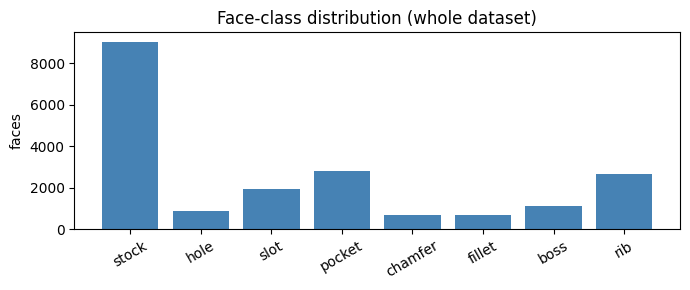

In [2]:
with open(GRAPHS_PATH, "rb") as f:
    graphs = pickle.load(f)
print(f"{len(graphs)} graphs | {sum(len(g['y']) for g in graphs)} faces | "
      f"avg {np.mean([len(g['y']) for g in graphs]):.1f} faces/part")

all_y = np.concatenate([g["y"] for g in graphs])
counts = np.bincount(all_y, minlength=N_CLS)
print(pd.DataFrame({"class": CLASS_NAMES, "faces": counts, "share_%": (100*counts/counts.sum()).round(1)}).to_string(index=False))

plt.figure(figsize=(7, 3)); plt.bar(CLASS_NAMES, counts, color="steelblue")
plt.ylabel("faces"); plt.title("Face-class distribution (whole dataset)"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## 3. Split by part, normalise, and batch
* Split is **by part** (800 / 100 / 100), so the test set contains geometries never seen in training.
* `area` and edge `length` are log-transformed (they span orders of magnitude), then all features are standardised using **training-set statistics only**.

In [3]:
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(graphs))
n_tr, n_va = int(TRAIN_FRAC*len(graphs)), int(VAL_FRAC*len(graphs))
idx_train, idx_val, idx_test = perm[:n_tr], perm[n_tr:n_tr+n_va], perm[n_tr+n_va:]
print("parts  train/val/test:", len(idx_train), len(idx_val), len(idx_test))

def raw_feats(g):
    x = g["x"].copy(); e = g["edge_attr"].copy()
    x[:, 3] = np.log1p(x[:, 3])      # area
    e[:, 0] = np.log1p(e[:, 0])      # edge length
    return x, e

X_tr = np.concatenate([raw_feats(graphs[i])[0] for i in idx_train])
E_tr = np.concatenate([raw_feats(graphs[i])[1] for i in idx_train])
x_mu, x_sd = X_tr.mean(0), X_tr.std(0).clip(min=1e-6)
e_mu, e_sd = E_tr.mean(0), E_tr.std(0).clip(min=1e-6)

def to_tensors(g):
    x, e = raw_feats(g)
    return dict(name=g["name"],
                x=torch.tensor((x - x_mu) / x_sd, dtype=torch.float32),
                edge_index=torch.tensor(g["edge_index"], dtype=torch.long),
                edge_attr=torch.tensor((e - e_mu) / e_sd, dtype=torch.float32),
                y=torch.tensor(g["y"], dtype=torch.long))
data = [to_tensors(g) for g in graphs]

def collate(items):
    xs, eis, eas, ys, bs, off = [], [], [], [], [], 0
    for i, g in enumerate(items):
        n = g["x"].shape[0]
        xs.append(g["x"]); eis.append(g["edge_index"] + off); eas.append(g["edge_attr"])
        ys.append(g["y"]); bs.append(torch.full((n,), i, dtype=torch.long)); off += n
    return dict(x=torch.cat(xs), edge_index=torch.cat(eis, 1), edge_attr=torch.cat(eas),
                y=torch.cat(ys), batch=torch.cat(bs))

def batches(idx, shuffle):
    idx = np.array(idx);
    if shuffle: idx = idx[np.random.permutation(len(idx))]
    for s in range(0, len(idx), BATCH_SIZE):
        b = collate([data[i] for i in idx[s:s+BATCH_SIZE]])
        yield {k: v.to(device) for k, v in b.items()}

# class weights from TRAIN faces only (inverse sqrt frequency, mean-normalised)
tr_counts = np.bincount(np.concatenate([graphs[i]["y"] for i in idx_train]), minlength=N_CLS)
w = (tr_counts.sum() / (N_CLS * tr_counts.clip(min=1))) ** 0.5
class_weights = torch.tensor(w / w.mean(), dtype=torch.float32, device=device)
print("class weights:", dict(zip(CLASS_NAMES, class_weights.cpu().numpy().round(2))))

parts  train/val/test: 800 100 100
class weights: {'stock': np.float32(0.4), 'hole': np.float32(1.3), 'slot': np.float32(0.85), 'pocket': np.float32(0.71), 'chamfer': np.float32(1.46), 'fillet': np.float32(1.44), 'boss': np.float32(1.12), 'rib': np.float32(0.72)}


## 4. Models
* **MLPNet** - per-face classifier, no neighbour information (baseline).
* **EdgeGNN** - message passing on the face-adjacency graph. Each layer builds a message from the neighbour's state **and the edge features** (length, dihedral angle, convex/concave/smooth), averages messages, and updates the face state with a residual connection.
  Setting `use_edge=False` hides the edge features (all-zero) so we can measure how much they matter.

In [4]:
class MLPNet(nn.Module):
    def __init__(self, in_dim=11, h=HIDDEN, n_layers=NUM_LAYERS, drop=DROPOUT):
        super().__init__()
        layers, d = [], in_dim
        for _ in range(n_layers):
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(drop)]; d = h
        self.net = nn.Sequential(*layers, nn.Linear(h, N_CLS))
    def forward(self, b): return self.net(b["x"])

class GNNLayer(nn.Module):
    def __init__(self, h, drop):
        super().__init__()
        self.msg  = nn.Sequential(nn.Linear(2*h, h), nn.ReLU(), nn.Linear(h, h))
        self.upd  = nn.Sequential(nn.Linear(2*h, h), nn.ReLU(), nn.Linear(h, h))
        self.norm = nn.LayerNorm(h); self.drop = nn.Dropout(drop)
    def forward(self, h, ei, e):
        src, dst = ei
        m = self.msg(torch.cat([h[src], e], -1))
        agg = torch.zeros_like(h).index_add_(0, dst, m)
        deg = torch.zeros(h.size(0), 1, device=h.device).index_add_(0, dst, torch.ones(dst.size(0), 1, device=h.device))
        agg = agg / deg.clamp(min=1)
        return self.norm(h + self.drop(self.upd(torch.cat([h, agg], -1))))

class EdgeGNN(nn.Module):
    def __init__(self, in_dim=11, e_dim=5, h=HIDDEN, n_layers=NUM_LAYERS, drop=DROPOUT, use_edge=True):
        super().__init__()
        self.use_edge = use_edge
        self.node_enc = nn.Linear(in_dim, h); self.edge_enc = nn.Linear(e_dim, h)
        self.layers = nn.ModuleList([GNNLayer(h, drop) for _ in range(n_layers)])
        self.head = nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Dropout(drop), nn.Linear(h, N_CLS))
    def forward(self, b):
        h = F.relu(self.node_enc(b["x"]))
        e = self.edge_enc(b["edge_attr"]) if self.use_edge else torch.zeros(b["edge_attr"].size(0), h.size(1), device=h.device)
        e = F.relu(e)
        for layer in self.layers: h = layer(h, b["edge_index"], e)
        return self.head(h)

MODELS = {"MLP baseline (no neighbours)": lambda: MLPNet(),
          "GNN (no edge features)":       lambda: EdgeGNN(use_edge=False),
          "GNN (with edge features)":     lambda: EdgeGNN(use_edge=True)}
for k, mk in MODELS.items():
    print(f"{k:32s} parameters: {sum(p.numel() for p in mk().parameters()):,}")

MLP baseline (no neighbours)     parameters: 13,768
GNN (no edge features)           parameters: 105,672
GNN (with edge features)         parameters: 105,672


## 5. Training and evaluation functions
Early stopping and model selection use **validation macro-F1** (not accuracy), because accuracy is dominated by the large *stock* class.

In [5]:
@torch.no_grad()
def predict(model, idx):
    """Returns y_true, y_pred, probs, part_id (index into `data`), mean loss for the parts in idx."""
    model.eval(); ys, ps, pid, tot, n = [], [], [], 0.0, 0
    for s in range(0, len(idx), BATCH_SIZE):
        chunk = idx[s:s+BATCH_SIZE]
        b = {k: v.to(device) for k, v in collate([data[i] for i in chunk]).items()}
        logits = model(b)
        tot += F.cross_entropy(logits, b["y"], weight=class_weights, reduction="sum").item(); n += len(b["y"])
        ys.append(b["y"].cpu().numpy()); ps.append(F.softmax(logits, -1).cpu().numpy())
        pid.append(np.array(chunk)[b["batch"].cpu().numpy()])
    probs = np.concatenate(ps)
    return np.concatenate(ys), probs.argmax(1), probs, np.concatenate(pid), tot / n

def macro_f1(y, p): return precision_recall_fscore_support(y, p, labels=range(N_CLS), average="macro", zero_division=0)[2]

def train_model(name, model):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=8)
    hist = dict(train_loss=[], val_loss=[], val_acc=[], val_f1=[]); best = (-1, None, 0); t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); tot, n = 0.0, 0
        for b in batches(idx_train, shuffle=True):
            opt.zero_grad(); loss = F.cross_entropy(model(b), b["y"], weight=class_weights)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            tot += loss.item() * len(b["y"]); n += len(b["y"])
        yv, pv, _, _, lv = predict(model, idx_val)
        f1 = macro_f1(yv, pv); sched.step(f1)
        hist["train_loss"].append(tot / n); hist["val_loss"].append(lv)
        hist["val_acc"].append(accuracy_score(yv, pv)); hist["val_f1"].append(f1)
        if f1 > best[0]: best = (f1, copy.deepcopy(model.state_dict()), ep)
        if ep % 10 == 0 or ep == 1:
            print(f"[{name}] ep {ep:3d} | train loss {hist['train_loss'][-1]:.4f} | val loss {lv:.4f} | val acc {hist['val_acc'][-1]:.4f} | val macro-F1 {f1:.4f}")
        if ep - best[2] >= PATIENCE:
            print(f"[{name}] early stop at epoch {ep} (best epoch {best[2]})"); break
    model.load_state_dict(best[1])
    return model, hist, best[2], time.time() - t0

## 6. Train all three models

In [6]:
trained, histories = {}, {}
for name, make in MODELS.items():
    set_seed(SEED)
    print("=" * 100, "\n", name, "\n", "=" * 100, sep="")
    model, hist, best_ep, secs = train_model(name, make())
    trained[name] = model; histories[name] = dict(hist=hist, best_epoch=best_ep, seconds=secs)
    print(f">> {name}: best epoch {best_ep}, {secs:.0f}s, best val macro-F1 {max(hist['val_f1']):.4f}\n")

MLP baseline (no neighbours)
[MLP baseline (no neighbours)] ep   1 | train loss 1.8621 | val loss 0.9944 | val acc 0.5829 | val macro-F1 0.3234
[MLP baseline (no neighbours)] ep  10 | train loss 0.9014 | val loss 0.5620 | val acc 0.7211 | val macro-F1 0.6043
[MLP baseline (no neighbours)] ep  20 | train loss 0.8091 | val loss 0.5086 | val acc 0.7547 | val macro-F1 0.6466
[MLP baseline (no neighbours)] ep  30 | train loss 0.7376 | val loss 0.4605 | val acc 0.7619 | val macro-F1 0.6726
[MLP baseline (no neighbours)] ep  40 | train loss 0.6595 | val loss 0.4018 | val acc 0.7838 | val macro-F1 0.7216
[MLP baseline (no neighbours)] ep  50 | train loss 0.6182 | val loss 0.3811 | val acc 0.7914 | val macro-F1 0.7293
[MLP baseline (no neighbours)] ep  60 | train loss 0.5845 | val loss 0.3625 | val acc 0.8027 | val macro-F1 0.7430
[MLP baseline (no neighbours)] ep  70 | train loss 0.5609 | val loss 0.3597 | val acc 0.8021 | val macro-F1 0.7502
[MLP baseline (no neighbours)] ep  80 | train loss 

### Learning curves

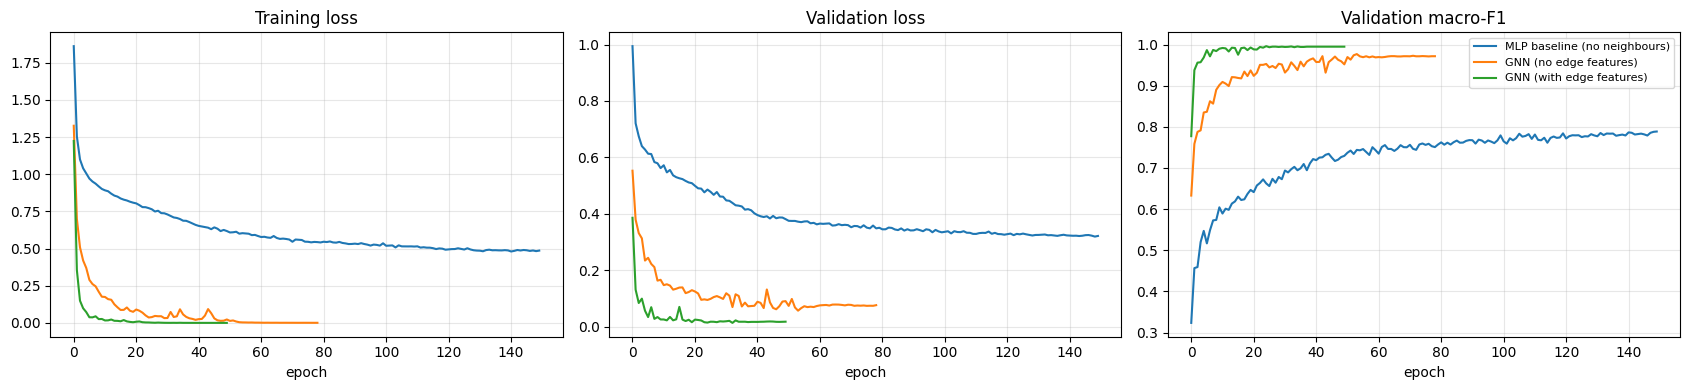

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for name, r in histories.items():
    h = r["hist"]
    ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_f1"], label=name)
for a, t in zip(ax, ["Training loss", "Validation loss", "Validation macro-F1"]):
    a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[2].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learning_curves.png", dpi=150); plt.show()

## 7. Full metric suite
`full_metrics` returns:
* **Overall:** accuracy, balanced accuracy, macro / weighted / micro precision-recall-F1, Cohen's kappa, Matthews correlation (MCC), log-loss, macro ROC-AUC (one-vs-rest), macro average-precision, mean IoU
* **Per class:** precision, recall, F1, IoU, ROC-AUC, average precision, support
* **Confusion matrix** (counts and row-normalised)
* **Part-level:** % of parts in which **every** face is classified correctly (the metric that matters for a real feature-recognition tool)

In [8]:
def full_metrics(model, idx):
    y, p, probs, pid, loss = predict(model, idx)
    labels = list(range(N_CLS))
    P, R, F, S = precision_recall_fscore_support(y, p, labels=labels, zero_division=0)
    cm = confusion_matrix(y, p, labels=labels)
    tp = np.diag(cm); iou = tp / (cm.sum(0) + cm.sum(1) - tp).clip(min=1)
    auc, ap = [], []
    for c in labels:
        yb = (y == c).astype(int)
        auc.append(roc_auc_score(yb, probs[:, c]) if 0 < yb.sum() < len(yb) else np.nan)
        ap.append(average_precision_score(yb, probs[:, c]) if yb.sum() > 0 else np.nan)
    part_ok = pd.Series(p == y).groupby(pid).all()
    overall = dict(
        accuracy=accuracy_score(y, p), balanced_accuracy=balanced_accuracy_score(y, p),
        macro_precision=P.mean(), macro_recall=R.mean(), macro_f1=F.mean(),
        weighted_f1=precision_recall_fscore_support(y, p, average="weighted", zero_division=0)[2],
        micro_f1=precision_recall_fscore_support(y, p, average="micro", zero_division=0)[2],
        cohen_kappa=cohen_kappa_score(y, p), mcc=matthews_corrcoef(y, p),
        log_loss=log_loss(y, probs, labels=labels), macro_roc_auc=np.nanmean(auc), macro_avg_precision=np.nanmean(ap),
        mean_iou=iou.mean(), part_exact_match=part_ok.mean(), n_faces=len(y), n_parts=len(part_ok))
    per_class = pd.DataFrame(dict(precision=P, recall=R, f1=F, iou=iou, roc_auc=auc, avg_precision=ap, support=S), index=CLASS_NAMES)
    return dict(overall=overall, per_class=per_class, cm=cm, y=y, p=p, pid=pid, part_ok=part_ok)

val_res  = {n: full_metrics(m, idx_val)  for n, m in trained.items()}
test_res = {n: full_metrics(m, idx_test) for n, m in trained.items()}

### 7a. Validation vs. test summary

In [9]:
def summary_table(res):
    return pd.DataFrame({n: r["overall"] for n, r in res.items()}).T

pd.set_option("display.width", 220, "display.max_columns", 30)
print("VALIDATION SET"); display(summary_table(val_res).round(4))
print("\nTEST SET (final, unseen parts)"); test_summary = summary_table(test_res); display(test_summary.round(4))

VALIDATION SET


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,micro_f1,cohen_kappa,mcc,log_loss,macro_roc_auc,macro_avg_precision,mean_iou,part_exact_match,n_faces,n_parts
MLP baseline (no neighbours),0.8307,0.7979,0.7911,0.7979,0.7885,0.8278,0.8307,0.7682,0.7700,0.4078,0.9778,0.8589,0.6796,0.06,1961.0,100.0
GNN (no edge features),0.9832,0.9756,0.9780,0.9756,0.9767,0.9832,0.9832,0.9769,0.9770,0.0637,0.9996,0.9961,0.9552,0.82,1961.0,100.0
GNN (with edge features),0.9959,0.9955,0.9965,0.9955,0.9960,0.9959,0.9959,0.9944,0.9944,0.0167,1.0000,0.9998,0.9921,0.95,1961.0,100.0



TEST SET (final, unseen parts)


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,micro_f1,cohen_kappa,mcc,log_loss,macro_roc_auc,macro_avg_precision,mean_iou,part_exact_match,n_faces,n_parts
MLP baseline (no neighbours),0.8338,0.8040,0.7933,0.8040,0.7947,0.8335,0.8338,0.7748,0.7754,0.4017,0.9780,0.8625,0.6889,0.08,1986.0,100.0
GNN (no edge features),0.9819,0.9713,0.9718,0.9713,0.9715,0.9819,0.9819,0.9754,0.9754,0.0858,0.9991,0.9907,0.9453,0.82,1986.0,100.0
GNN (with edge features),0.9945,0.9938,0.9933,0.9938,0.9935,0.9945,0.9945,0.9925,0.9925,0.0318,0.9998,0.9989,0.9872,0.92,1986.0,100.0


### 7b. Test-set per-class report for every model

In [10]:
for n, r in test_res.items():
    print("\n" + "=" * 90 + f"\n{n}  -  TEST per-class metrics\n" + "=" * 90)
    display(r["per_class"].round(4))


MLP baseline (no neighbours)  -  TEST per-class metrics


,precision,recall,f1,iou,roc_auc,avg_precision,support
stock,0.9786,0.9634,0.9709,0.9435,0.9968,0.9963,902
hole,0.8590,0.7882,0.8221,0.6979,0.9914,0.8898,85
slot,0.5267,0.4413,0.4802,0.3160,0.9158,0.5230,179
pocket,0.6842,0.7485,0.7149,0.5563,0.9614,0.8035,330
chamfer,1.0000,0.9722,0.9859,0.9722,0.9988,0.9903,72
fillet,0.9254,0.9841,0.9538,0.9118,0.9994,0.9768,63
boss,0.5933,0.8396,0.6953,0.5329,0.9876,0.8563,106
rib,0.7793,0.6948,0.7346,0.5805,0.9727,0.8637,249



GNN (no edge features)  -  TEST per-class metrics


,precision,recall,f1,iou,roc_auc,avg_precision,support
stock,0.9989,0.9945,0.9967,0.9934,0.9989,0.9993,902
hole,0.9302,0.9412,0.9357,0.8791,0.9969,0.9776,85
slot,0.9444,0.9497,0.9471,0.8995,0.9988,0.9889,179
pocket,0.9757,0.9727,0.9742,0.9497,0.9992,0.9960,330
chamfer,0.9861,0.9861,0.9861,0.9726,0.9999,0.9980,72
fillet,1.0000,0.9683,0.9839,0.9683,1.0000,0.9998,63
boss,0.9623,0.9623,0.9623,0.9273,0.9990,0.9671,106
rib,0.9764,0.9960,0.9861,0.9725,0.9998,0.9988,249



GNN (with edge features)  -  TEST per-class metrics


,precision,recall,f1,iou,roc_auc,avg_precision,support
stock,0.9978,0.9989,0.9983,0.9967,0.9991,0.9994,902
hole,0.9884,1.0000,0.9942,0.9884,1.0000,1.0000,85
slot,0.9672,0.9888,0.9779,0.9568,0.9996,0.9969,179
pocket,0.9969,0.9788,0.9878,0.9758,0.9995,0.9956,330
chamfer,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,72
fillet,1.0000,0.9841,0.9920,0.9841,1.0000,0.9998,63
boss,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,106
rib,0.9960,1.0000,0.9980,0.9960,1.0000,0.9999,249


### 7c. Confusion matrices (test set)
Left: raw counts. Right: row-normalised (each row = true class, shows recall and where errors go).

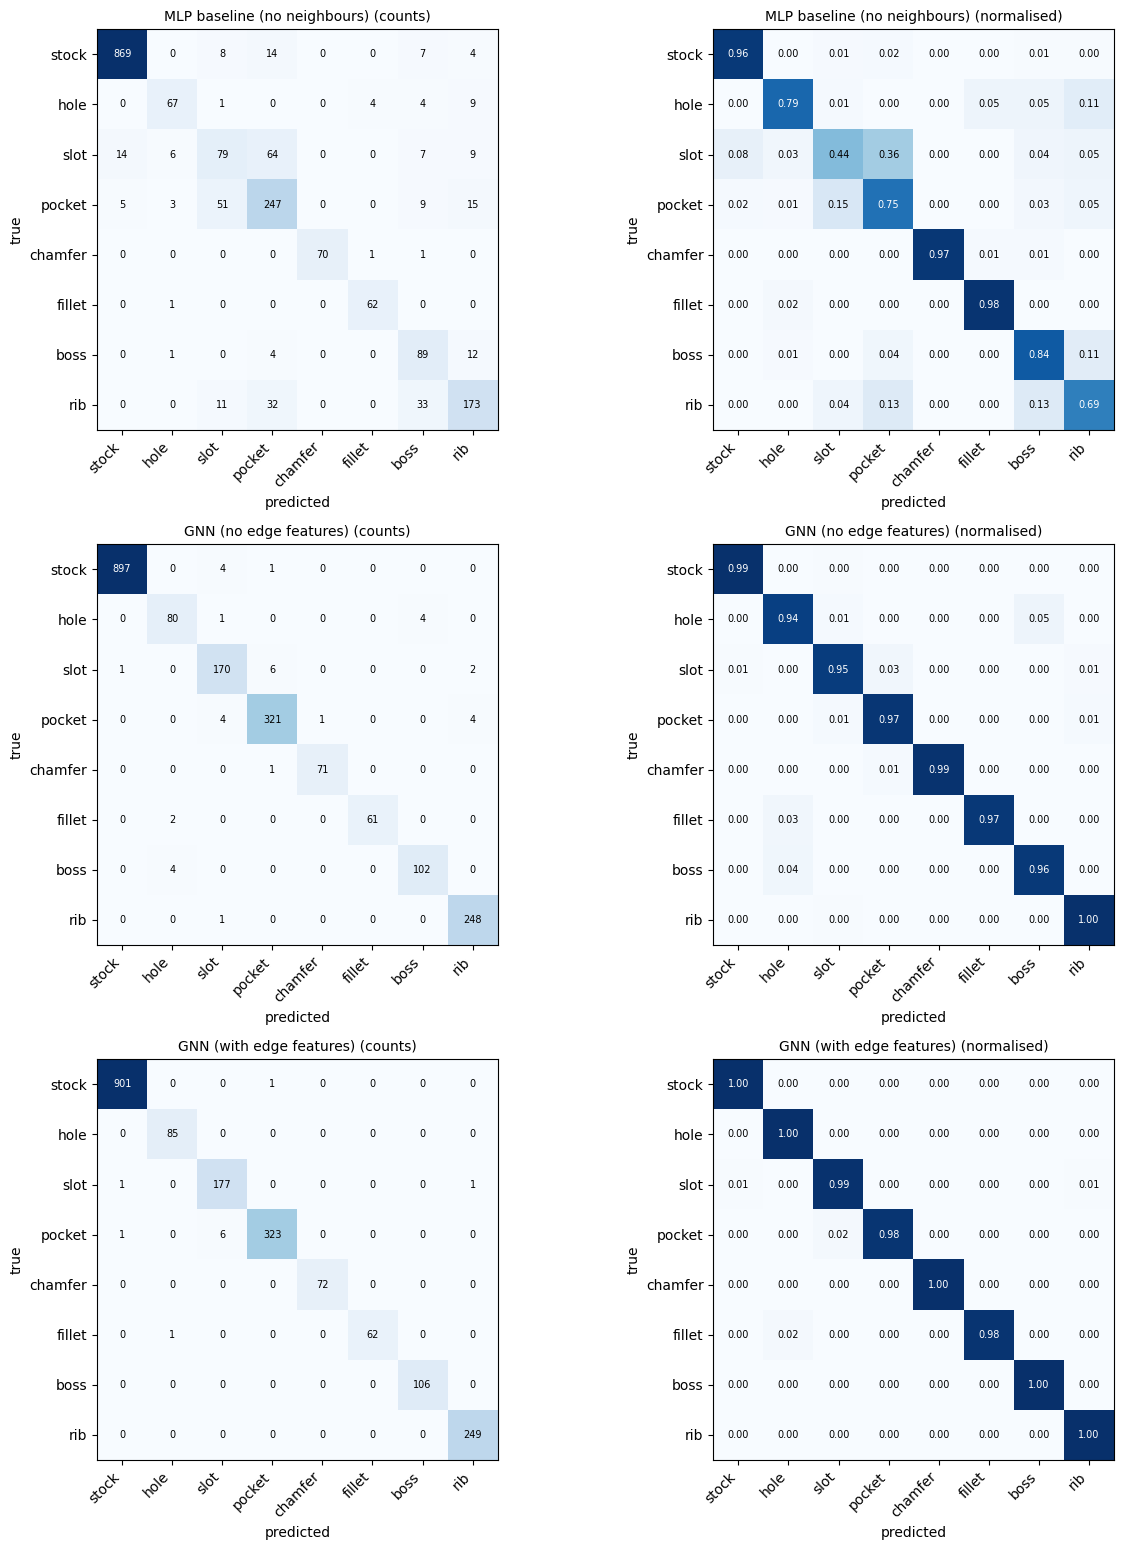

In [11]:
def plot_cm(cm, title, ax, normalise):
    m = cm / cm.sum(1, keepdims=True).clip(min=1) if normalise else cm
    ax.imshow(m, cmap="Blues", vmin=0, vmax=1 if normalise else None)
    ax.set_xticks(range(N_CLS)); ax.set_yticks(range(N_CLS))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10)
    for i in range(N_CLS):
        for j in range(N_CLS):
            v = m[i, j]; ax.text(j, i, f"{v:.2f}" if normalise else int(v), ha="center", va="center",
                                 color="white" if v > (0.5 if normalise else m.max()/2) else "black", fontsize=7)

fig, axes = plt.subplots(len(test_res), 2, figsize=(13, 5.2 * len(test_res)))
for row, (n, r) in enumerate(test_res.items()):
    plot_cm(r["cm"], n + " (counts)", axes[row, 0], False); plot_cm(r["cm"], n + " (normalised)", axes[row, 1], True)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150); plt.show()

### 7d. Model comparison - per-class F1 and key metrics

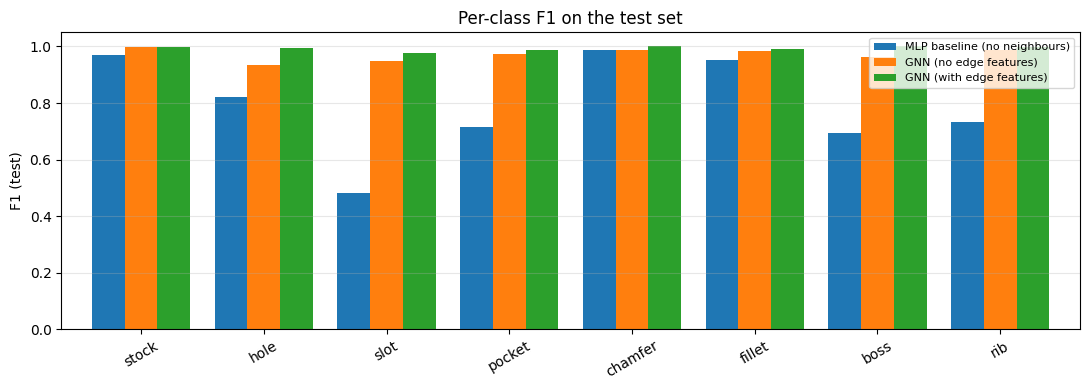

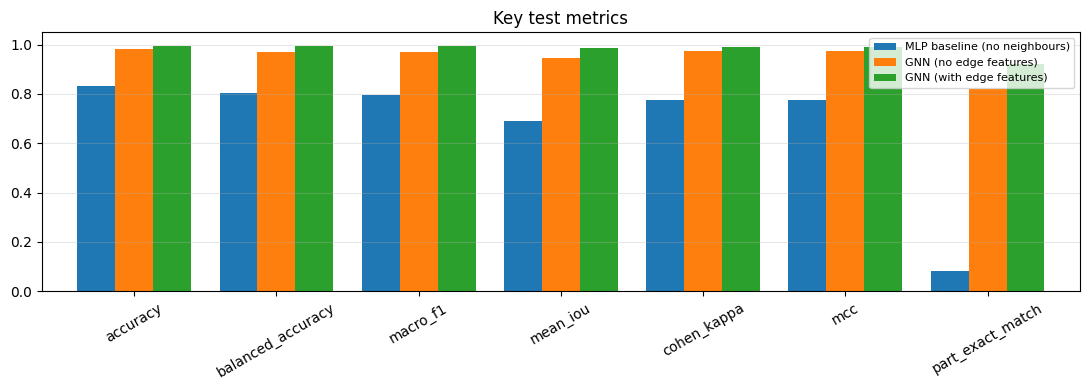

In [12]:
f1_table = pd.DataFrame({n: r["per_class"]["f1"] for n, r in test_res.items()})
ax = f1_table.plot(kind="bar", figsize=(11, 4), width=0.8); ax.set_ylabel("F1 (test)"); ax.set_ylim(0, 1.05)
ax.set_title("Per-class F1 on the test set"); ax.grid(axis="y", alpha=.3); plt.xticks(rotation=30); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/per_class_f1.png", dpi=150); plt.show()

key = ["accuracy", "balanced_accuracy", "macro_f1", "mean_iou", "cohen_kappa", "mcc", "part_exact_match"]
ax = test_summary[key].T.plot(kind="bar", figsize=(11, 4), width=0.8); ax.set_ylim(0, 1.05)
ax.set_title("Key test metrics"); ax.grid(axis="y", alpha=.3); plt.xticks(rotation=30); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/key_metrics.png", dpi=150); plt.show()

## 8. Error analysis (best model)
Observing

Which classes get confused, and which test parts contain mistakes?

In [13]:
best_name = test_summary["macro_f1"].astype(float).idxmax()
r = test_res[best_name]; print("Best model on test macro-F1:", best_name)

cm = r["cm"].copy(); np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(N_CLS) for j in range(N_CLS) if cm[i, j] > 0), reverse=True)[:8]
print("\nMost frequent confusions (true -> predicted):")
for n, t, p in pairs: print(f"  {t:8s} -> {p:8s} : {n} faces")

bad = r["part_ok"][~r["part_ok"]].index
print(f"\n{len(bad)} of {len(r['part_ok'])} test parts contain at least one wrong face:")
for pid_ in bad[:15]:
    mask = r["pid"] == pid_
    wrong = [(CLASS_NAMES[t], CLASS_NAMES[p]) for t, p in zip(r["y"][mask], r["p"][mask]) if t != p]
    print(f"  {data[pid_]['name']}: {len(wrong)} wrong of {mask.sum()} faces ->", wrong[:4])

Best model on test macro-F1: GNN (with edge features)

Most frequent confusions (true -> predicted):
  pocket   -> slot     : 6 faces
  stock    -> pocket   : 1 faces
  slot     -> stock    : 1 faces
  slot     -> rib      : 1 faces
  pocket   -> stock    : 1 faces
  fillet   -> hole     : 1 faces

8 of 100 test parts contain at least one wrong face:
  part_00099: 1 wrong of 22 faces -> [('slot', 'stock')]
  part_00252: 1 wrong of 18 faces -> [('stock', 'pocket')]
  part_00276: 1 wrong of 19 faces -> [('pocket', 'slot')]
  part_00413: 4 wrong of 20 faces -> [('pocket', 'slot'), ('pocket', 'slot'), ('pocket', 'slot'), ('pocket', 'slot')]
  part_00475: 1 wrong of 19 faces -> [('pocket', 'stock')]
  part_00476: 1 wrong of 19 faces -> [('fillet', 'hole')]
  part_00484: 1 wrong of 29 faces -> [('slot', 'rib')]
  part_00646: 1 wrong of 26 faces -> [('pocket', 'slot')]


## 9. Save model and results

In [14]:
torch.save(trained[best_name].state_dict(), f"{OUT_DIR}/best_model.pt")
test_summary.to_csv(f"{OUT_DIR}/test_summary.csv"); summary_table(val_res).to_csv(f"{OUT_DIR}/val_summary.csv")
for i, (n, rr) in enumerate(test_res.items()):
    rr["per_class"].to_csv(f"{OUT_DIR}/test_per_class_model{i}.csv")
json.dump({"best_model": best_name, "config": dict(HIDDEN=HIDDEN, NUM_LAYERS=NUM_LAYERS, LR=LR, EPOCHS=EPOCHS, SEED=SEED),
           "split_parts": [len(idx_train), len(idx_val), len(idx_test)]}, open(f"{OUT_DIR}/run_info.json", "w"), indent=2)
print("saved to", os.path.abspath(OUT_DIR))

saved to /content/results


In [15]:
import shutil
from google.colab import files

# Compress the results directory to results.zip
shutil.make_archive('results', 'zip', 'results')

# Trigger browser download of the zip file
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>